# 04: Neural networks (Unit 4)

1. **Perceptron:** the single-neuron ancestor, run on the sanity task.
2. **MLP regressor:** compare activations, optimizers, learning rates and network sizes, with loss curves.
3. **5 seeds:** a neural net's result depends on its random starting weights, so we report mean ± spread, not a single lucky run.
4. **Against 02:** does the MLP beat the simple chosen models by more than 0.02 R²? If not, the selection stands.

> **Honesty note.** The labels come from `backend/services/scheme_rules.py` plus Gaussian noise. They are not real scheme allocations or eligibility decisions. A model scoring near the **R² ceiling** has recovered those rules. That is the best possible result here, and it says nothing about real-world accuracy, because no real outcome data exists yet. A score *above* the ceiling would mean leakage.

## 0. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ML = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fra_ml.py").exists() or (p / "ml" / "fra_ml.py").exists())
ML = ML if (ML / "fra_ml.py").exists() else ML / "ml"
sys.path.insert(0, str(ML))
from fra_ml import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (8, 4.5)})
pd.set_option("display.width", 200, "display.max_columns", 40)

df = load_data()
train, test = split(df)
print(f"train {len(train)} rows / {train.spatial_block.nunique()} blocks | test {len(test)} rows / {test.spatial_block.nunique()} blocks")
print("test rows per district:", test.district.value_counts().to_dict())

from sklearn.base import clone
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def mlp(**kw):
    base = dict(hidden_layer_sizes=(32, 16), activation="relu", solver="adam", learning_rate_init=1e-3,
                alpha=1e-3, max_iter=800, n_iter_no_change=20, random_state=SEED)
    base.update(kw)
    return MLPRegressor(**base)

def cv_r2(model, t="mgnrega_score"):
    return cross_val_score(make_pipe(model), X_of(train), train[t], cv=group_cv(), groups=train.spatial_block,
                           scoring="r2", n_jobs=-1).mean()

train 1211 rows / 92 blocks | test 329 rows / 23 blocks
test rows per district: {'Adilabad': 80, 'Shivpuri': 74, 'West Tripura': 72, 'Chhindwara': 32, 'Kandhamal': 31, 'Warangal': 29, 'Koraput': 11}


## 1. The perceptron
A perceptron computes a weighted sum of the inputs plus a bias and outputs 1 if it is above 0: $\hat y = \text{step}(w \cdot x + b)$. After every mistake it nudges the weights toward the right answer. It can only learn a **straight-line boundary**. The sanity task ("pm_kisan > 50" ⇔ IFR) is a straight line on one feature, so a single neuron should solve it perfectly.

In [2]:
ys_tr, ys_te = (train.pm_kisan_score > 50).astype(int), (test.pm_kisan_score > 50).astype(int)
per = make_pipe(Perceptron(random_state=SEED)).fit(X_of(train), ys_tr)
print(f"perceptron test accuracy: {accuracy_score(ys_te, per.predict(X_of(test))):.3f}")
w = pd.Series(per.named_steps["model"].coef_[0], index=MODEL_FEATURES).round(2)
w.sort_values(key=abs, ascending=False)

perceptron test accuracy: 1.000


is_ifr                    7.10
is_cfr                   -1.72
land_area_ha             -1.31
rainfall_mm_avg          -1.27
small_holding             0.93
ph_band                  -0.92
groundwater_stress_pct   -0.57
soil_ph                   0.31
oc_pct                    0.29
dtype: float64

The largest weight lands on `is_ifr`: the perceptron found the rule by itself. A *tercile* problem, or any curved boundary, is beyond a single neuron, which is why we stack neurons into layers.

## 2. How an MLP learns (the short version)
- **Forward pass:** input → hidden layer 1 (32 neurons) → hidden layer 2 (16) → one output. Each neuron computes $a = f(w \cdot x + b)$ with an **activation** $f$:
  - **ReLU** $\max(0, z)$: simple and fast, the modern default.
  - **tanh**: S-shaped, outputs −1…1.
  - **logistic (sigmoid)**: S-shaped, outputs 0…1. It saturates easily, which makes learning slow.
- **Loss:** squared error between prediction and label (sklearn reports ½·MSE).
- **Backpropagation:** the chain rule gives the gradient of the loss with respect to every weight, working backwards from the output.
- **Gradient descent:** weights ← weights − *learning rate* × gradient.
  - **SGD** takes plain steps on small batches.
  - **Adam** adapts the step size for each weight.
  - **L-BFGS** is a full-batch quasi-Newton method: strong on small datasets like this one, but it has no per-epoch loss curve.
- **alpha** is L2 regularisation: it penalises big weights to fight overfitting.

All comparisons below use **mgnrega**, the only continuous multi-factor label, scored by GroupKFold CV R² (ceiling 0.583).

## 3. Activation × optimizer

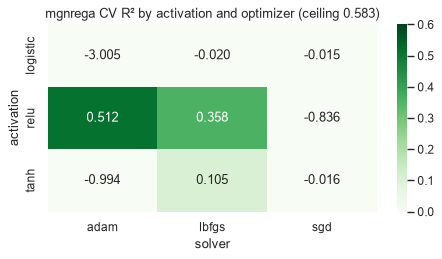

solver,adam,lbfgs,sgd
activation,,,
logistic,-3.005,-0.020,-0.015
relu,0.512,0.358,-0.836
tanh,-0.994,0.105,-0.016


In [3]:
grid = []
for act in ["relu", "tanh", "logistic"]:
    for solver in ["adam", "sgd", "lbfgs"]:
        kw = {"activation": act, "solver": solver}
        if solver == "sgd": kw["learning_rate_init"] = 1e-2
        grid.append({"activation": act, "solver": solver, "CV R²": cv_r2(mlp(**kw))})
act_tab = pd.DataFrame(grid).pivot(index="activation", columns="solver", values="CV R²")
fig, ax = plt.subplots(figsize=(6, 3.4))
sns.heatmap(act_tab, annot=True, fmt=".3f", cmap="Greens", vmin=0, vmax=0.6, ax=ax)
ax.set_title("mgnrega CV R² by activation and optimizer (ceiling 0.583)"); plt.tight_layout(); plt.show()
act_tab.round(3)

## 4. Learning rate and loss curves

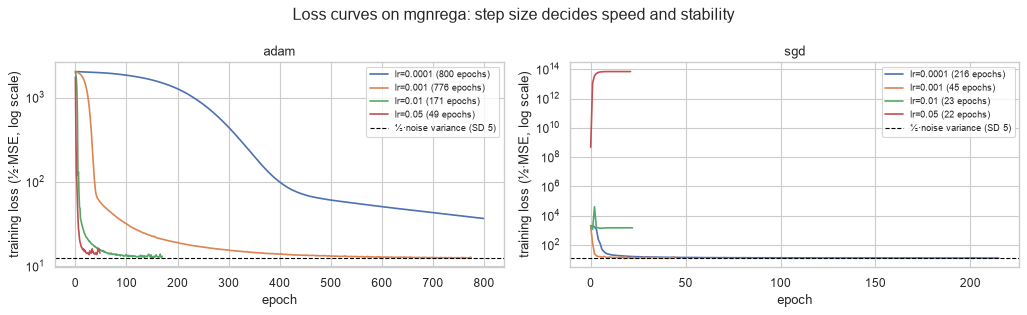

,solver,learning rate,CV R²,epochs,final train loss
0,adam,0.0001,-0.813,800,36.83
1,adam,0.001,0.512,776,12.62
2,adam,0.01,0.514,171,13.10
3,adam,0.05,0.497,49,14.32
4,sgd,0.0001,0.528,216,12.67
5,sgd,0.001,0.526,45,15.08
6,sgd,0.01,-0.836,23,1.5e+03
7,sgd,0.05,-2.7e+79 (diverged),22,7.0e+13


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lr_rows = []
for ax, solver in zip(axes, ["adam", "sgd"]):
    for lr in [1e-4, 1e-3, 1e-2, 5e-2]:
        m = make_pipe(mlp(solver=solver, learning_rate_init=lr)).fit(X_of(train), train.mgnrega_score)
        curve = m.named_steps["model"].loss_curve_
        ax.plot(curve, label=f"lr={lr:g} ({len(curve)} epochs)")
        lr_rows.append({"solver": solver, "learning rate": f"{lr:g}", "CV R²": cv_r2(mlp(solver=solver, learning_rate_init=lr)),
                        "epochs": len(curve), "final train loss": curve[-1]})
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("training loss (½·MSE, log scale)")
    ax.axhline(5.0 ** 2 / 2, color="black", ls="--", lw=1, label="½·noise variance (SD 5)")
    ax.set_title(solver); ax.legend(fontsize=8)
fig.suptitle("Loss curves on mgnrega: step size decides speed and stability"); plt.tight_layout(); plt.show()
lr_tab = pd.DataFrame(lr_rows)
lr_tab["CV R²"] = lr_tab["CV R²"].map(lambda v: f"{v:.3f}" if v > -10 else f"{v:.1e} (diverged)")
lr_tab["final train loss"] = lr_tab["final train loss"].map(lambda v: f"{v:.2f}" if v < 1e3 else f"{v:.1e}")
lr_tab

**Reading the curves:**
- **Too small a learning rate** crawls and may stop (no improvement for 20 epochs) before it reaches a good fit.
- **Too large a rate** jumps around, or flattens at a worse loss.
- The dashed line is ½ × the label-noise variance. A training loss far *below* it means the network has started memorising noise (overfitting).

## 5. Network size and regularisation (bias vs variance again)

In [5]:
size_rows = []
for hidden in [(4,), (16,), (32, 16), (64, 32), (128, 64, 32)]:
    for alpha in [1e-4, 1e-2, 1.0]:
        m = make_pipe(mlp(hidden_layer_sizes=hidden, alpha=alpha)).fit(X_of(train), train.mgnrega_score)
        size_rows.append({"hidden layers": str(hidden), "alpha": f"{alpha:g}",
                          "train R²": r2_score(train.mgnrega_score, m.predict(X_of(train))),
                          "CV R²": cv_r2(mlp(hidden_layer_sizes=hidden, alpha=alpha))})
size_tab = pd.DataFrame(size_rows)
size_tab["gap (train − CV)"] = size_tab["train R²"] - size_tab["CV R²"]
size_tab.round(3)

,hidden layers,alpha,train R²,CV R²,gap (train − CV)
0,"(4,)",0.0001,-1.937,-6.958,5.020
1,"(4,)",0.01,-1.937,-6.958,5.021
2,"(4,)",1,-1.996,-6.995,5.000
3,"(16,)",0.0001,0.454,0.171,0.283
4,"(16,)",0.01,0.454,0.171,0.283
5,"(16,)",1,0.455,0.157,0.298
6,"(32, 16)",0.0001,0.592,0.515,0.076
7,"(32, 16)",0.01,0.591,0.512,0.079
8,"(32, 16)",1,0.591,0.507,0.084
9,"(64, 32)",0.0001,0.594,0.511,0.083


A bigger network raises **train** R², but CV R² stays capped near the ceiling, so the growing gap is pure variance. A larger `alpha` (stronger L2 penalty) narrows the gap.

## 6. Final MLP config × 5 seeds, on the three primary targets
We take the best activation/optimizer/size/alpha from §3–5 (on mgnrega CV only, not test) and run it with 5 different random seeds.

In [6]:
best_act, best_solver = act_tab.stack().idxmax()
best_size = size_tab.loc[size_tab["CV R²"].idxmax()]
CONFIG = {"activation": best_act, "solver": best_solver,
          "hidden_layer_sizes": tuple(int(x) for x in best_size["hidden layers"].strip("(),").split(",") if x.strip()),
          "alpha": float(best_size["alpha"])}
if best_solver == "sgd": CONFIG["learning_rate_init"] = 1e-2
print("chosen MLP config:", CONFIG)

seed_rows, seed42_rows = [], []
for t in PRIMARY:
    for seed in [0, 1, 2, 3, 42]:
        row, _ = evaluate(make_pipe(mlp(**CONFIG, random_state=seed)), train, test, t, "MLP")
        row["seed"] = seed; seed_rows.append(row)
        if seed == SEED: seed42_rows.append(row)
seeds = pd.DataFrame(seed_rows)
summary = seeds.groupby("target").agg(cv_R2_mean=("cv_R2", "mean"), cv_R2_sd=("cv_R2", "std"),
                                      test_R2_mean=("test_R2", "mean"), test_R2_sd=("test_R2", "std"),
                                      test_oracle_R2=("test_oracle_R2", "first"))
summary.round(3)

chosen MLP config: {'activation': 'relu', 'solver': 'adam', 'hidden_layer_sizes': (64, 32), 'alpha': 0.01}


,cv_R2_mean,cv_R2_sd,test_R2_mean,test_R2_sd,test_oracle_R2
target,,,,,
mgnrega_score,0.528,0.004,0.533,0.005,0.629
pmksy_score,0.896,0.003,0.880,0.004,0.896
soil_health_card_score,0.834,0.004,0.724,0.012,0.893


## 7. Against the models chosen in 02

In [7]:
cmp = pd.read_csv(RESULTS_DIR / "model_comparison.csv")
cmp = cmp[cmp.notebook != "04_neural_net"]           # idempotent re-runs
chosen02 = cmp[cmp.chosen].set_index("target")
best02 = cmp[(cmp.notebook == "02_regression") & ~cmp.model.str.startswith("baseline")].groupby("target").cv_R2.max()

verdict = []
for t in PRIMARY:
    mlp_cv = summary.loc[t, "cv_R2_mean"]
    verdict.append({"target": SHORT[t], "chosen in 02": chosen02.loc[t, "model"], "chosen CV R²": chosen02.loc[t, "cv_R2"],
                    "best 02 CV R²": best02[t], "MLP CV R² (5-seed mean)": mlp_cv,
                    "MLP test R² (mean ± sd)": f"{summary.loc[t, 'test_R2_mean']:.3f} ± {summary.loc[t, 'test_R2_sd']:.3f}",
                    "MLP beats best by > 0.02?": bool(mlp_cv > best02[t] + 0.02)})
verdict = pd.DataFrame(verdict).set_index("target")
display(verdict.round(3))
print("Selection changes:" , "YES, review the chosen models" if verdict["MLP beats best by > 0.02?"].any() else "no, the 02 choices stand (the MLP is the most complex model, so it only wins by a clear margin)")

,chosen in 02,chosen CV R²,best 02 CV R²,MLP CV R² (5-seed mean),MLP test R² (mean ± sd),MLP beats best by > 0.02?
target,,,,,,
mgnrega,decision tree,0.546,0.550,0.528,0.533 ± 0.005,False
pmksy,multiple linear,0.896,0.915,0.896,0.880 ± 0.004,False
soil_health_card,decision tree,0.917,0.917,0.834,0.724 ± 0.012,False


Selection changes: no, the 02 choices stand (the MLP is the most complex model, so it only wins by a clear margin)


In [8]:
mlp_rows = pd.DataFrame(seed42_rows)
mlp_rows["model"] = "MLP " + str(CONFIG["hidden_layer_sizes"])
mlp_rows["params"] = json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in CONFIG.items()})
mlp_rows = mlp_rows.drop(columns="seed")
mlp_rows["chosen"] = False; mlp_rows["notebook"] = "04_neural_net"
mlp_rows = mlp_rows.merge(summary[["test_R2_sd", "cv_R2_sd"]].rename(columns={"test_R2_sd": "seed_sd_test_R2", "cv_R2_sd": "seed_sd_cv_R2"}),
                          left_on="target", right_index=True)
out = pd.concat([cmp, mlp_rows], ignore_index=True)
num = out.select_dtypes("number").columns; out[num] = out[num].round(4)
out.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
print("appended", len(mlp_rows), "MLP rows (seed 42; 5-seed sd in seed_sd_* columns) to model_comparison.csv")

appended 3 MLP rows (seed 42; 5-seed sd in seed_sd_* columns) to model_comparison.csv


## 8. Takeaways (numbers from the run above)
- **The perceptron solves the sanity task (100%)** and puts its biggest weight on `is_ifr`: a single neuron recovers a one-line rule.
- **Optimizer and learning rate matter a lot:**
  - SGD at lr 0.01 and 0.05 **diverged**, with the loss exploding to about 10¹³.
  - Adam at 1e-4 hadn't converged after 800 epochs (CV R² negative).
  - Adam at 1e-3 to 1e-2 and SGD at 1e-4 to 1e-3 all land near CV 0.51–0.53.
- **Size shows bias vs variance:**
  - **(4,): collapse.** CV R² is −7: a tiny ReLU net whose neurons "die" and output garbage.
  - **(16,): underfits.**
  - **(32,16) and (64,32): best**, at CV ≈ 0.51.
  - **(128,64,32): overfitting.** The train–CV gap grows to about 0.10.
- **alpha** barely matters at these sizes.
- **5 seeds give a tight spread** (test R² sd ≤ 0.012), so the result isn't a lucky draw.
- **The MLP never beats the 02 models.**
  - **mgnrega:** 0.528 vs 0.550 CV.
  - **pmksy:** ties multiple linear at 0.896.
  - **soil_health_card:** clearly worse (test 0.72 vs the tree's 0.89). The rule is a set of hard *steps* (pH/OC bands), and a smooth network approximates steps with a ramp, while a tree draws them exactly.
- **Verdict:** the 02 selection stands. On rule-plus-noise labels a neural net has nothing extra to find, and it costs tuning, seed variance and explainability.